ПРАКТИЧЕСКАЯ РАБОТА №7
РЕГРЕССИОННЫЙ АНАЛИЗ ДАННЫХ

ЗАДАНИЕ 1
Обучающий файл загружен. Форма: (4398, 13)

Первые 5 строк train_data:
   uranium_lead_ratio  carbon_14_ratio  radioactive_decay_series  \
0            0.738061         0.487707                  0.907884   
1            0.560096         0.341738                  1.121302   
2            0.424773         0.218493                  0.103855   
3            0.349958         0.704649                  0.383617   
4            0.886811         0.777494                  0.593254   

   stratigraphic_layer_depth geological_period paleomagnetic_data  \
0                      91.17        Cretaceous    Normal polarity   
1                     165.44          Cambrian    Normal polarity   
2                     218.98          Cambrian    Normal polarity   
3                      51.09           Permian    Normal polarity   
4                     313.72          Devonian    Normal polarity   

   inclusion_of_other_fossils  isotopic_com

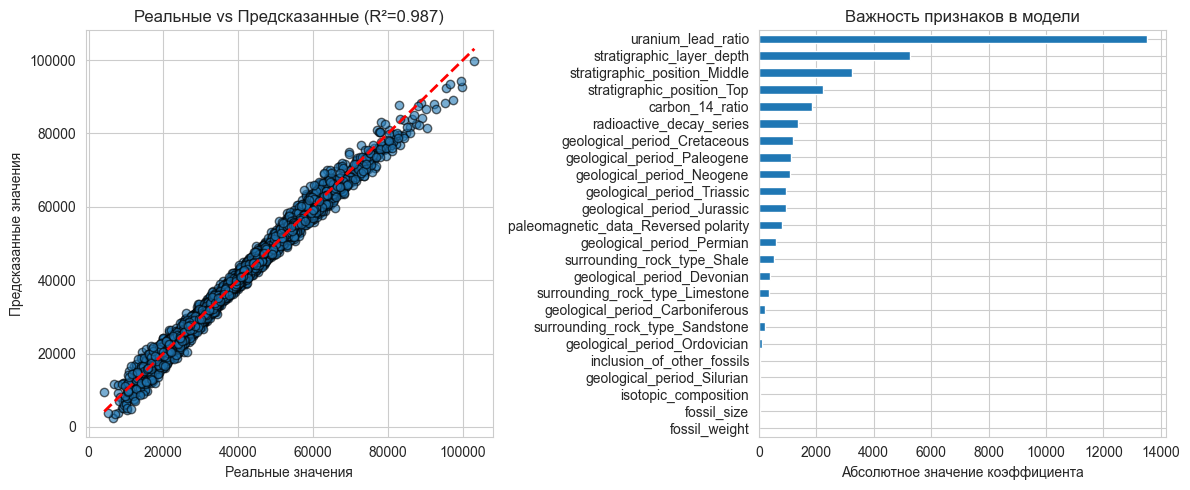


Предсказания на тестовых данных:
  Min: 849.22, Max: 90834.85, Mean: 41190.78

----------------------------------------
Генерация 10 новых наблюдений и предсказание возраста
----------------------------------------

Сгенерированные данные и предсказания:
   uranium_lead_ratio  carbon_14_ratio  radioactive_decay_series  \
0                0.61             0.32                      0.95   
1                0.45             0.32                      0.47   
2                0.65             0.49                      0.55   
3                0.88            -0.02                      0.12   
4                0.43             0.03                      0.38   
5                0.43             0.30                      0.56   
6                0.89             0.19                      0.20   
7                0.68             0.50                      0.64   
8                0.37             0.22                      0.36   
9                0.63             0.10                      0.45

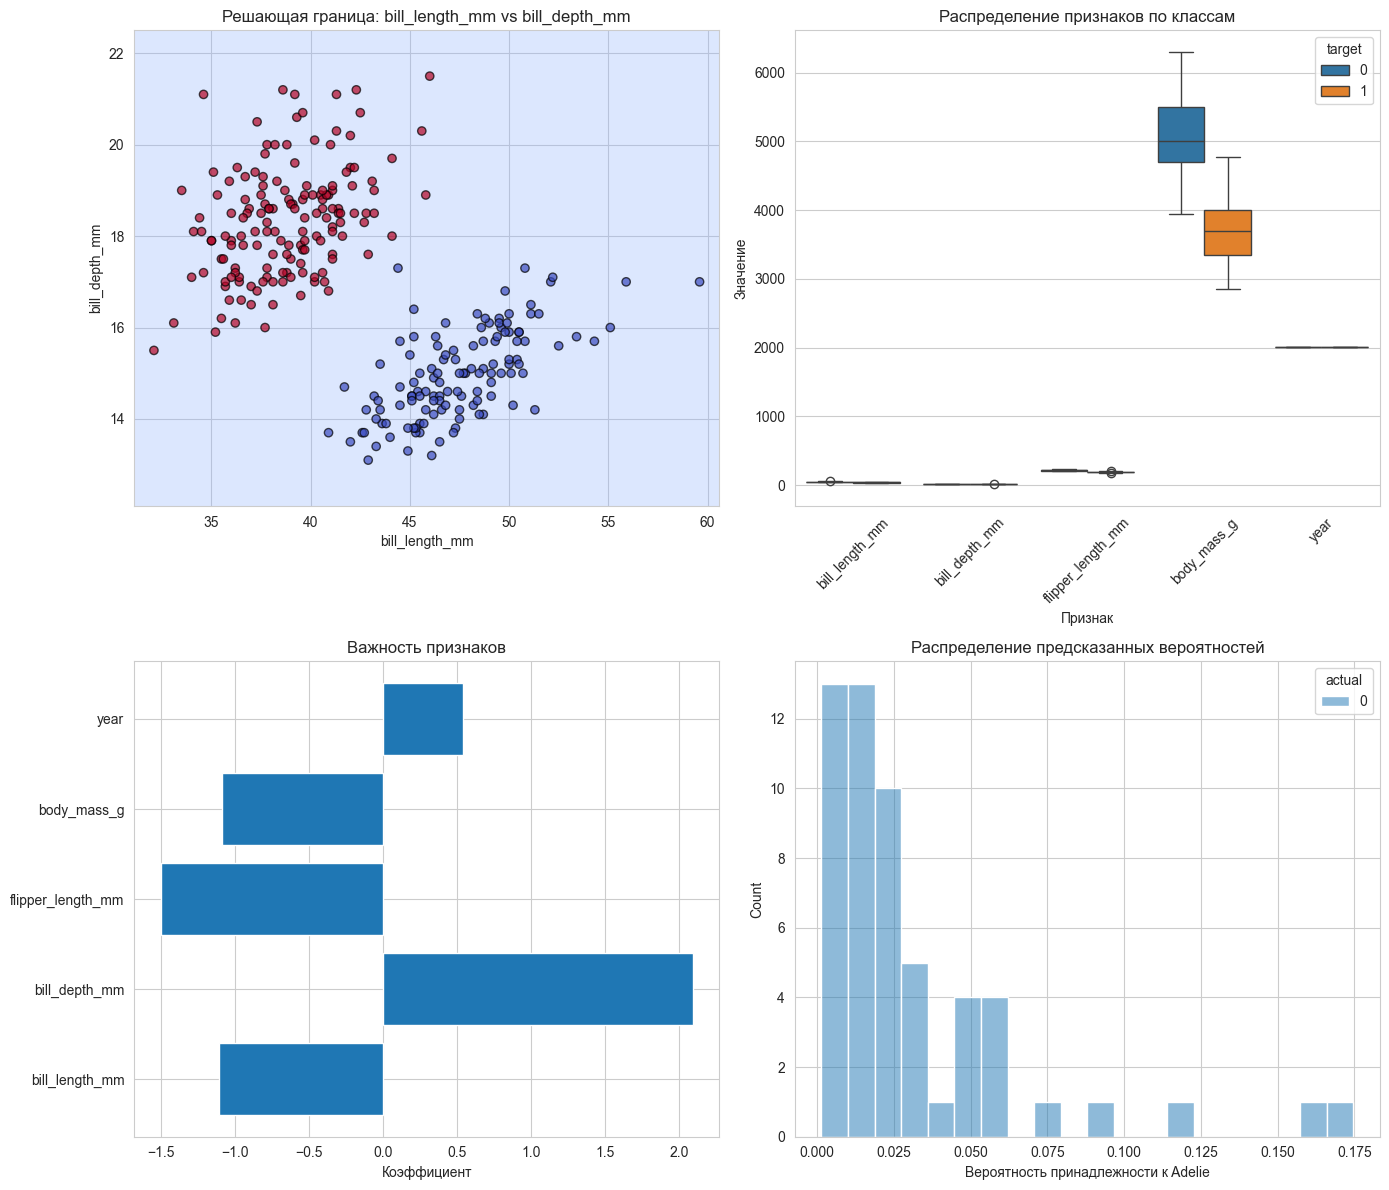


ЗАДАНИЕ *
Файл загружен. Форма: (18835, 15)

Первые 5 строк:
                    song_name  song_popularity  song_duration_ms  \
0  Boulevard of Broken Dreams               73            262333   
1                  In The End               66            216933   
2           Seven Nation Army               76            231733   
3                  By The Way               74            216933   
4           How You Remind Me               56            223826   

   acousticness  danceability  energy  instrumentalness  key  liveness  \
0      0.005520         0.496   0.682          0.000029    8    0.0589   
1      0.010300         0.542   0.853          0.000000    3    0.1080   
2      0.008170         0.737   0.463          0.447000    0    0.2550   
3      0.026400         0.451   0.970          0.003550    0    0.1020   
4      0.000954         0.447   0.766          0.000000   10    0.1130   

   loudness  audio_mode  speechiness    tempo  time_signature  audio_valence  
0    

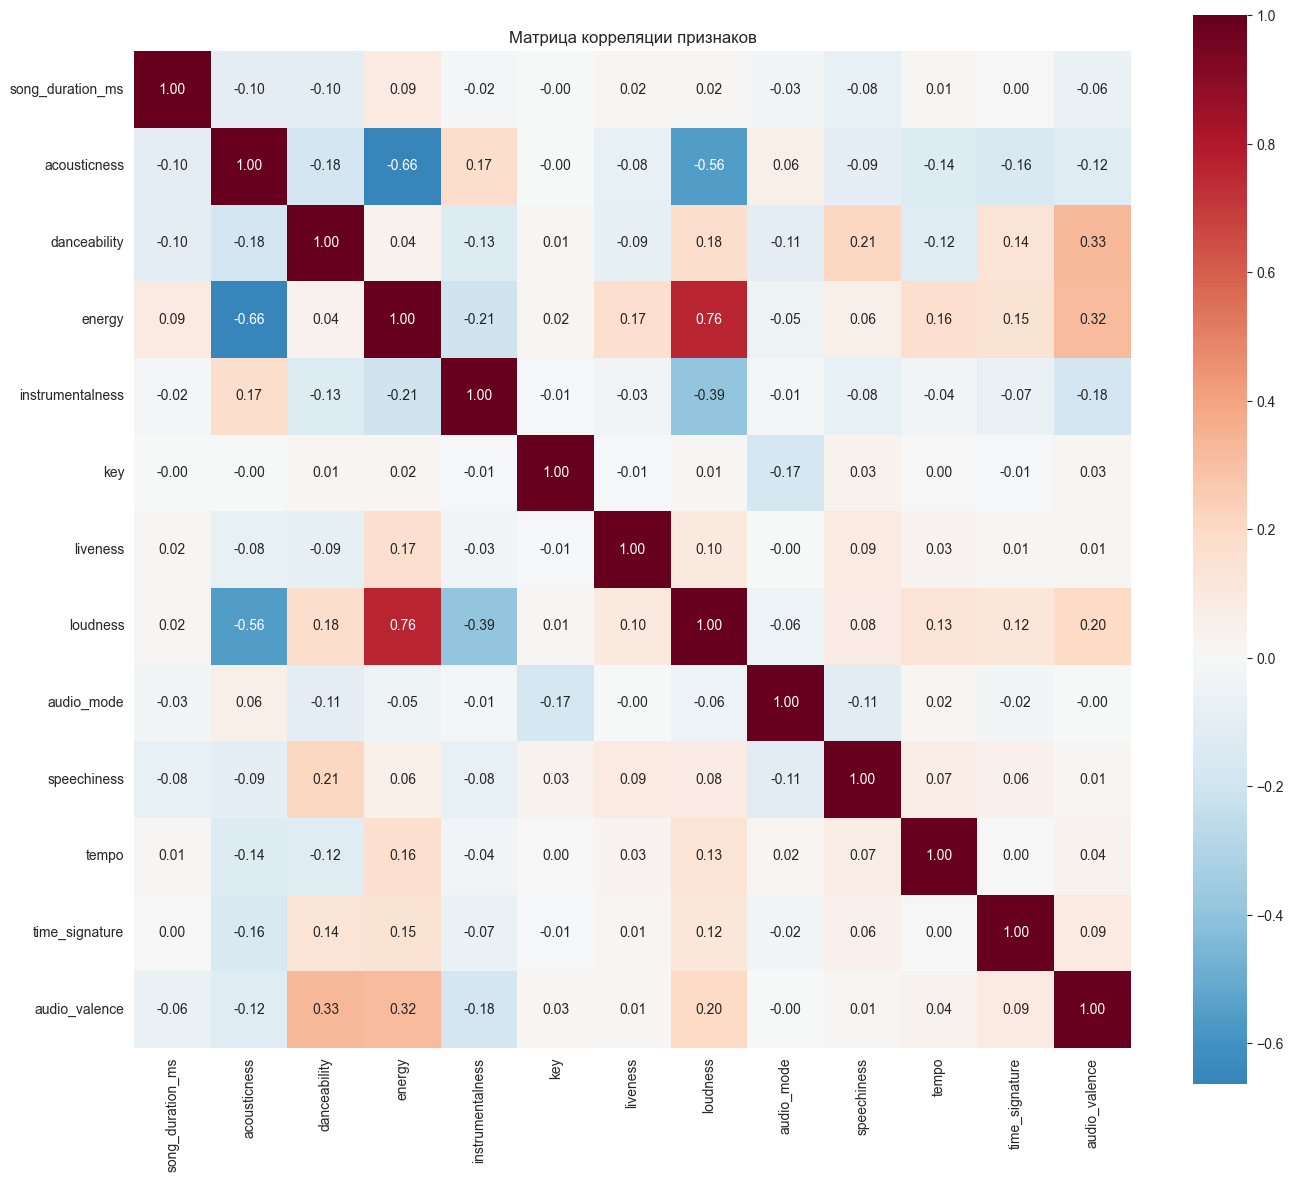


VIF (Variance Inflation Factor):
             feature        VIF
11    time_signature  88.901818
3             energy  30.732653
2       danceability  21.625450
10             tempo  18.285176
0   song_duration_ms  14.265089
7           loudness  11.940959
12     audio_valence   7.716693
5                key   3.208983
1       acousticness   3.177762
8         audio_mode   2.805870
6           liveness   2.681362
9        speechiness   2.154095
4   instrumentalness   1.400073

Примечание: VIF > 10 указывает на сильную мультиколлинеарность

Обучающая выборка: 15068 записей
Тестовая выборка: 3767 записей

----------------------------------------
Модель 1: Множественная линейная регрессия
----------------------------------------
R²: 0.0456
RMSE: 21.9978
MAE: 17.5085

----------------------------------------
Модель 2: Ридж-регрессия (Ridge)
----------------------------------------
Лучший alpha: 0.01
R²: 0.0456
RMSE: 21.9978
MAE: 17.5085

----------------------------------------
Модель 3: 

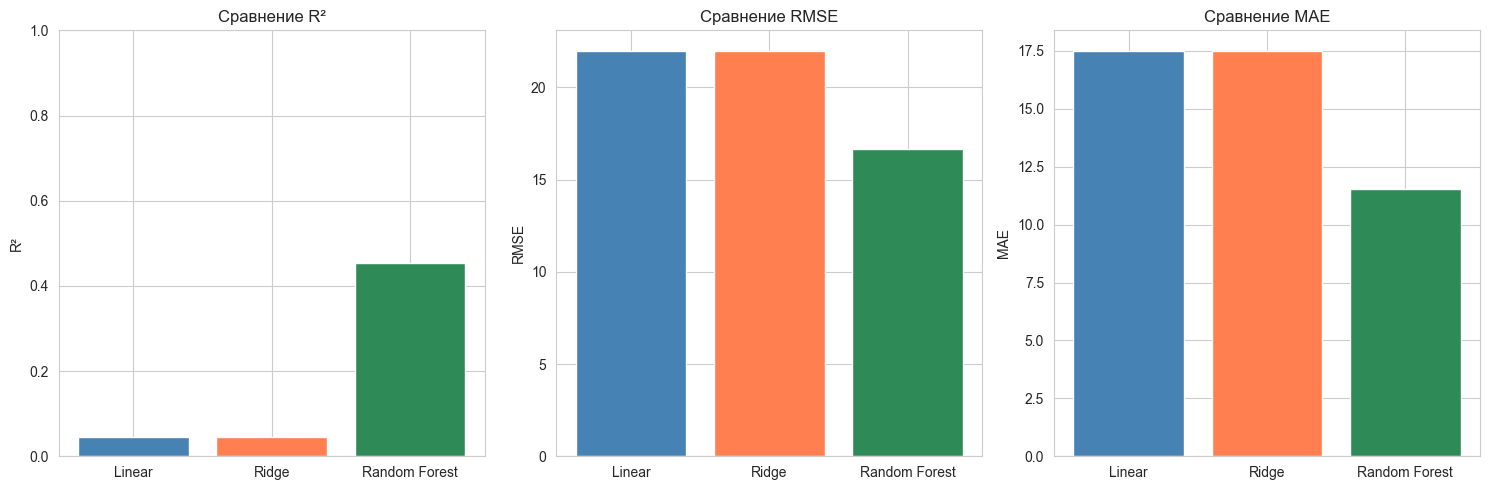

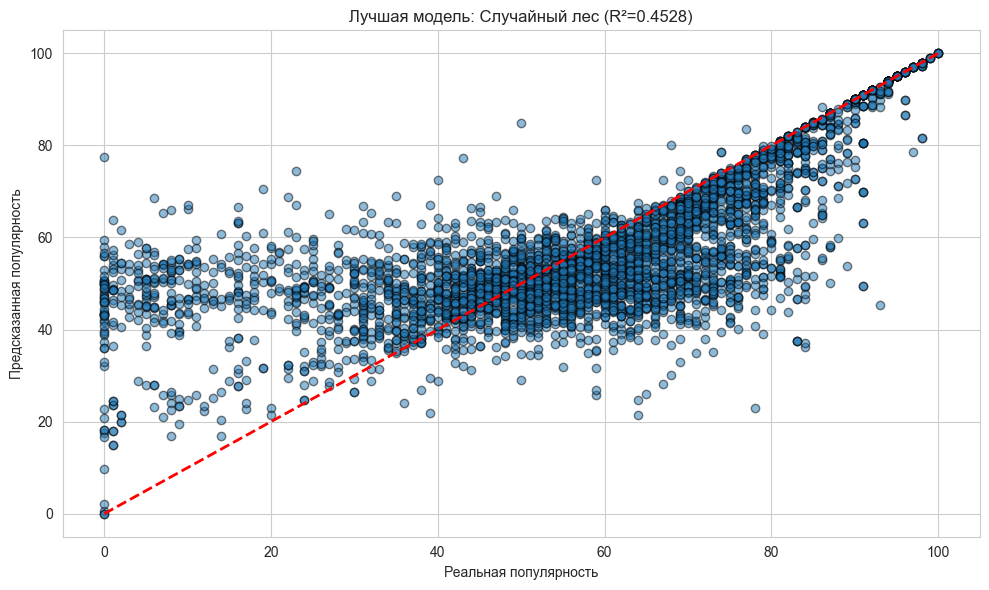


ВЫВОДЫ ПО РАБОТЕ

Задание 1
  - Построена модель линейной регрессии с R²=0.9867
  - R² >= 0.8 - условие выполнено

Задание 2
  - Точность модели: 1.0000

Задание * (Song Popularity):
  - Линейная регрессия: R²=0.0456
  - Ридж-регрессия: R²=0.0456
  - Случайный лес: R²=0.4528
  - Лучшая модель: Случайный лес



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("ПРАКТИЧЕСКАЯ РАБОТА №7")
print("РЕГРЕССИОННЫЙ АНАЛИЗ ДАННЫХ")
print("="*60)

# ============================================================
# ЗАДАНИЕ 1
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ 1")
print("="*60)

TRAIN_FILE = "data/train_data.csv"
TEST_FILE = "data/test_data.csv"

try:
    df_train = pd.read_csv(TRAIN_FILE)
    print(f"Обучающий файл загружен. Форма: {df_train.shape}")
    print("\nПервые 5 строк train_data:")
    print(df_train.head())
except FileNotFoundError:
    print(f"Ошибка: файл '{TRAIN_FILE}' не найден")
    exit(1)
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

try:
    df_test = pd.read_csv(TEST_FILE)
    print(f"\nТестовый файл загружен. Форма: {df_test.shape}")
    print("\nПервые 5 строк test_data:")
    print(df_test.head())
except FileNotFoundError:
    print(f"Ошибка: файл '{TEST_FILE}' не найден")
    exit(1)
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

print("\nИнформация о train_data:")
df_train.info()

print("\nОписательная статистика train_data:")
print(df_train.describe())

# Целевая переменная
target_col = 'age'
if target_col not in df_train.columns:
    for col in df_train.columns:
        if 'age' in col.lower():
            target_col = col
            break

print(f"\nЦелевая переменная: {target_col}")

# Отбор признаков (исключаем нечисловые и целевую)
feature_cols = []
for col in df_train.columns:
    if col != target_col and pd.api.types.is_numeric_dtype(df_train[col]):
        feature_cols.append(col)

print(f"Числовые признаки для модели: {feature_cols}")

# Обработка категориальных признаков
categorical_cols = []
for col in df_train.columns:
    if col != target_col and not pd.api.types.is_numeric_dtype(df_train[col]):
        categorical_cols.append(col)

if categorical_cols:
    print(f"\nКатегориальные признаки: {categorical_cols}")
    df_train = pd.get_dummies(df_train, columns=categorical_cols, drop_first=True)
    df_test = pd.get_dummies(df_test, columns=categorical_cols, drop_first=True)
    for col in df_train.columns:
        if col not in df_test.columns and col != target_col:
            df_test[col] = 0
    for col in df_test.columns:
        if col not in df_train.columns and col != target_col:
            df_train[col] = 0
    feature_cols = [col for col in df_train.columns if col != target_col]

# Обработка пропусков
for col in feature_cols + [target_col]:
    if df_train[col].isna().sum() > 0:
        df_train[col] = df_train[col].fillna(df_train[col].median())
    if col in df_test.columns and df_test[col].isna().sum() > 0:
        df_test[col] = df_test[col].fillna(df_train[col].median())

# Подготовка данных
X_train = df_train[feature_cols].values
y_train = df_train[target_col].values
X_test = df_test[feature_cols].values

print(f"\nРазмер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

# Нормализация
scaler_fossil = StandardScaler()
X_train_scaled = scaler_fossil.fit_transform(X_train)
X_test_scaled = scaler_fossil.transform(X_test)

# Модель
model_fossil = LinearRegression()
model_fossil.fit(X_train_scaled, y_train)

y_train_pred = model_fossil.predict(X_train_scaled)
r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

print(f"\nМодель линейной регрессии:")
print(f"  R² на обучении: {r2_train:.4f}")
print(f"  RMSE на обучении: {rmse_train:.2f}")

print(f"\nКоэффициенты модели:")
for i, col in enumerate(feature_cols):
    print(f"  {col}: {model_fossil.coef_[i]:.4f}")
print(f"  intercept: {model_fossil.intercept_:.4f}")

# Визуализация
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_train, y_train_pred, alpha=0.6, edgecolors='k')
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
plt.xlabel('Реальные значения')
plt.ylabel('Предсказанные значения')
plt.title(f'Реальные vs Предсказанные (R²={r2_train:.3f})')

plt.subplot(1, 2, 2)
coef_series = pd.Series(model_fossil.coef_, index=feature_cols)
coef_series.abs().sort_values().plot(kind='barh')
plt.xlabel('Абсолютное значение коэффициента')
plt.title('Важность признаков в модели')
plt.tight_layout()
plt.show()

# Предсказания на тесте
test_predictions = model_fossil.predict(X_test_scaled)
print(f"\nПредсказания на тестовых данных:")
print(f"  Min: {test_predictions.min():.2f}, Max: {test_predictions.max():.2f}, Mean: {test_predictions.mean():.2f}")

# Генерация 10 новых наблюдений
print("\n" + "-"*40)
print("Генерация 10 новых наблюдений и предсказание возраста")
print("-"*40)

np.random.seed(42)
n_new = 10
new_data = {}

for col in feature_cols:
    if col in df_train.columns:
        mean_val = df_train[col].mean()
        std_val = df_train[col].std()
        new_data[col] = np.random.normal(mean_val, std_val, n_new)

new_df = pd.DataFrame(new_data)
new_scaled = scaler_fossil.transform(new_df.values)
new_predictions = model_fossil.predict(new_scaled)

print("\nСгенерированные данные и предсказания:")
new_df['predicted_age'] = new_predictions
print(new_df.round(2))

print(f"\nПредсказанный возраст: от {new_predictions.min():.2f} до {new_predictions.max():.2f}")
print(f"Среднее предсказание: {new_predictions.mean():.2f}")

# ============================================================
# ЗАДАНИЕ 2
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ 2")
print("="*60)

PENGUINS_FILE = "data/penguins_binary_classification.csv"

try:
    df_penguins = pd.read_csv(PENGUINS_FILE)
    print(f"Файл загружен. Форма: {df_penguins.shape}")
    print("\nПервые 5 строк:")
    print(df_penguins.head())
except FileNotFoundError:
    print(f"Ошибка: файл '{PENGUINS_FILE}' не найден")
    exit(1)
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

print("\nУникальные значения species:")
print(df_penguins['species'].unique())

df_penguins['target'] = (df_penguins['species'] == 'Adelie').astype(int)
print(f"\nРаспределение классов:\n{df_penguins['target'].value_counts()}")

num_features = [col for col in df_penguins.columns if pd.api.types.is_numeric_dtype(df_penguins[col]) and col != 'target']
print(f"Числовые признаки: {num_features}")

for col in num_features:
    if df_penguins[col].isna().sum() > 0:
        df_penguins[col] = df_penguins[col].fillna(df_penguins[col].median())

X_peng = df_penguins[num_features].values
y_peng = df_penguins['target'].values

scaler_peng = StandardScaler()
X_peng_scaled = scaler_peng.fit_transform(X_peng)

split_idx = int(0.8 * len(X_peng))
X_train_peng, X_test_peng = X_peng_scaled[:split_idx], X_peng_scaled[split_idx:]
y_train_peng, y_test_peng = y_peng[:split_idx], y_peng[split_idx:]

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_peng, y_train_peng)

y_pred_peng = log_reg.predict(X_test_peng)
y_pred_proba = log_reg.predict_proba(X_test_peng)[:, 1]

accuracy = accuracy_score(y_test_peng, y_pred_peng)
print(f"\nТочность модели: {accuracy:.4f}")

# Матрица ошибок с проверкой размерности
cm = confusion_matrix(y_test_peng, y_pred_peng)
print("\nМатрица ошибок:")
if cm.shape == (1, 1):
    print(f"  Все предсказания верны (только один класс в тестовой выборке)")
    print(f"  Матрица: {cm[0][0]} правильных предсказаний")
else:
    cm_df = pd.DataFrame(cm, columns=['Predicted 0', 'Predicted 1'], index=['Actual 0', 'Actual 1'])
    print(cm_df)

print(f"\nКоэффициенты модели:")
for i, col in enumerate(num_features):
    print(f"  {col}: {log_reg.coef_[0][i]:.4f}")
print(f"  intercept: {log_reg.intercept_[0]:.4f}")

# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

feature1, feature2 = num_features[0], num_features[1]

x_min, x_max = df_penguins[feature1].min() - 1, df_penguins[feature1].max() + 1
y_min, y_max = df_penguins[feature2].min() - 1, df_penguins[feature2].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

grid_input = np.c_[xx.ravel(), yy.ravel()]
for _ in range(len(num_features) - 2):
    grid_input = np.c_[grid_input, np.zeros(grid_input.shape[0])]
grid_scaled = scaler_peng.transform(grid_input)
Z = log_reg.predict(grid_scaled)
Z = Z.reshape(xx.shape)

axes[0,0].contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
scatter = axes[0,0].scatter(df_penguins[feature1], df_penguins[feature2],
                            c=df_penguins['target'], cmap='coolwarm', edgecolors='k', alpha=0.7)
axes[0,0].set_xlabel(feature1)
axes[0,0].set_ylabel(feature2)
axes[0,0].set_title(f'Решающая граница: {feature1} vs {feature2}')

data_melt = df_penguins.melt(id_vars=['target'], value_vars=num_features,
                             var_name='Признак', value_name='Значение')
sns.boxplot(data=data_melt, x='Признак', y='Значение', hue='target', ax=axes[0,1])
axes[0,1].set_title('Распределение признаков по классам')
axes[0,1].set_xticklabels(axes[0,1].get_xticklabels(), rotation=45)

axes[1,0].barh(num_features, log_reg.coef_[0])
axes[1,0].set_xlabel('Коэффициент')
axes[1,0].set_title('Важность признаков')

sns.histplot(data=pd.DataFrame({'probability': y_pred_proba, 'actual': y_test_peng}),
             x='probability', hue='actual', bins=20, ax=axes[1,1])
axes[1,1].set_title('Распределение предсказанных вероятностей')
axes[1,1].set_xlabel('Вероятность принадлежности к Adelie')

plt.tight_layout()
plt.show()

# ============================================================
# ЗАДАНИЕ *
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ *")
print("="*60)

SONG_FILE = "data/song_data.csv"

try:
    df_song = pd.read_csv(SONG_FILE)
    print(f"Файл загружен. Форма: {df_song.shape}")
    print("\nПервые 5 строк:")
    print(df_song.head())
except FileNotFoundError:
    print(f"Ошибка: файл '{SONG_FILE}' не найден")
    exit(1)
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

print("\nИнформация о данных:")
df_song.info()

target = 'song_popularity'
if target not in df_song.columns:
    target = 'popularity'
    if target not in df_song.columns:
        target = df_song.columns[1]

print(f"\nЦелевая переменная: {target}")

feature_cols_song = [col for col in df_song.columns if col != target and pd.api.types.is_numeric_dtype(df_song[col])]
print(f"Числовые признаки: {feature_cols_song}")

for col in feature_cols_song + [target]:
    if df_song[col].isna().sum() > 0:
        df_song[col] = df_song[col].fillna(df_song[col].median())

print("\n" + "-"*40)
print("Проверка на мультиколлинеарность")
print("-"*40)

corr_matrix = df_song[feature_cols_song].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt='.2f', square=True)
plt.title('Матрица корреляции признаков')
plt.tight_layout()
plt.show()

X_song = df_song[feature_cols_song].values
vif_data = pd.DataFrame()
vif_data['feature'] = feature_cols_song
vif_data['VIF'] = [variance_inflation_factor(X_song, i) for i in range(len(feature_cols_song))]
print("\nVIF (Variance Inflation Factor):")
print(vif_data.sort_values('VIF', ascending=False))
print("\nПримечание: VIF > 10 указывает на сильную мультиколлинеарность")

X_song = df_song[feature_cols_song].values
y_song = df_song[target].values

scaler_song = StandardScaler()
X_song_scaled = scaler_song.fit_transform(X_song)

split_idx_song = int(0.8 * len(X_song))
X_train_song, X_test_song = X_song_scaled[:split_idx_song], X_song_scaled[split_idx_song:]
y_train_song, y_test_song = y_song[:split_idx_song], y_song[split_idx_song:]

print(f"\nОбучающая выборка: {X_train_song.shape[0]} записей")
print(f"Тестовая выборка: {X_test_song.shape[0]} записей")

# 1. Линейная регрессия
print("\n" + "-"*40)
print("Модель 1: Множественная линейная регрессия")
print("-"*40)

lr_model = LinearRegression()
lr_model.fit(X_train_song, y_train_song)
y_pred_lr = lr_model.predict(X_test_song)

r2_lr = r2_score(y_test_song, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test_song, y_pred_lr))
mae_lr = mean_absolute_error(y_test_song, y_pred_lr)

print(f"R²: {r2_lr:.4f}")
print(f"RMSE: {rmse_lr:.4f}")
print(f"MAE: {mae_lr:.4f}")

# 2. Ридж-регрессия
print("\n" + "-"*40)
print("Модель 2: Ридж-регрессия (Ridge)")
print("-"*40)

alphas = [0.01, 0.1, 1, 10, 100]
best_ridge = None
best_r2 = -np.inf
best_alpha = None

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_song, y_train_song)
    r2 = r2_score(y_test_song, ridge.predict(X_test_song))
    if r2 > best_r2:
        best_r2 = r2
        best_ridge = ridge
        best_alpha = alpha

print(f"Лучший alpha: {best_alpha}")
print(f"R²: {best_r2:.4f}")

y_pred_ridge = best_ridge.predict(X_test_song)
rmse_ridge = np.sqrt(mean_squared_error(y_test_song, y_pred_ridge))
mae_ridge = mean_absolute_error(y_test_song, y_pred_ridge)
print(f"RMSE: {rmse_ridge:.4f}")
print(f"MAE: {mae_ridge:.4f}")

# 3. Случайный лес
print("\n" + "-"*40)
print("Модель 3: Случайный лес (Random Forest)")
print("-"*40)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_song, y_train_song)
y_pred_rf = rf_model.predict(X_test_song)

r2_rf = r2_score(y_test_song, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_song, y_pred_rf))
mae_rf = mean_absolute_error(y_test_song, y_pred_rf)

print(f"R²: {r2_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"MAE: {mae_rf:.4f}")

feature_importance = pd.DataFrame({
    'feature': feature_cols_song,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nВажность признаков (Random Forest):")
print(feature_importance.head(10))

# Сравнение моделей
print("\n" + "="*60)
print("СРАВНЕНИЕ МОДЕЛЕЙ")
print("="*60)

comparison = pd.DataFrame({
    'Модель': ['Линейная регрессия', 'Ридж-регрессия', 'Случайный лес'],
    'R²': [r2_lr, best_r2, r2_rf],
    'RMSE': [rmse_lr, rmse_ridge, rmse_rf],
    'MAE': [mae_lr, mae_ridge, mae_rf]
})
print(comparison.to_string(index=False))

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = ['Linear', 'Ridge', 'Random Forest']
r2_scores = [r2_lr, best_r2, r2_rf]
colors = ['steelblue', 'coral', 'seagreen']

axes[0].bar(models, r2_scores, color=colors)
axes[0].set_ylabel('R²')
axes[0].set_title('Сравнение R²')
axes[0].set_ylim(0, 1)

axes[1].bar(models, [rmse_lr, rmse_ridge, rmse_rf], color=colors)
axes[1].set_ylabel('RMSE')
axes[1].set_title('Сравнение RMSE')

axes[2].bar(models, [mae_lr, mae_ridge, mae_rf], color=colors)
axes[2].set_ylabel('MAE')
axes[2].set_title('Сравнение MAE')

plt.tight_layout()
plt.show()

# Лучшая модель
best_model_name = "Случайный лес" if r2_rf == max(r2_lr, best_r2, r2_rf) else ("Ридж-регрессия" if best_r2 == max(r2_lr, best_r2, r2_rf) else "Линейная регрессия")
best_y_pred = y_pred_rf if r2_rf == max(r2_lr, best_r2, r2_rf) else (y_pred_ridge if best_r2 == max(r2_lr, best_r2, r2_rf) else y_pred_lr)

plt.figure(figsize=(10, 6))
plt.scatter(y_test_song, best_y_pred, alpha=0.5, edgecolors='k')
plt.plot([y_test_song.min(), y_test_song.max()], [y_test_song.min(), y_test_song.max()], 'r--', lw=2)
plt.xlabel('Реальная популярность')
plt.ylabel('Предсказанная популярность')
plt.title(f'Лучшая модель: {best_model_name} (R²={max(r2_lr, best_r2, r2_rf):.4f})')
plt.tight_layout()
plt.show()

# Выводы
print("\n" + "="*60)
print("ВЫВОДЫ ПО РАБОТЕ")
print("="*60)

print("\nЗадание 1")
print(f"  - Построена модель линейной регрессии с R²={r2_train:.4f}")
print(f"  - {'R² >= 0.8 - условие выполнено' if r2_train >= 0.8 else 'R² < 0.8 - модель требует улучшения'}")

print("\nЗадание 2")
print(f"  - Точность модели: {accuracy:.4f}")

print("\nЗадание * (Song Popularity):")
print(f"  - Линейная регрессия: R²={r2_lr:.4f}")
print(f"  - Ридж-регрессия: R²={best_r2:.4f}")
print(f"  - Случайный лес: R²={r2_rf:.4f}")
print(f"  - Лучшая модель: {best_model_name}")

print("\n" + "="*60)